# Step 1: Install Required Package

Install the UCI Machine Learning Repository package to access the CDC Diabetes Health Indicators dataset.

In [5]:
!pip install -q ucimlrepo

# Step 2: Import Required Libraries

Import the Python libraries required for data processing, visualization, model training and evaluation.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


# Step 3: Load the CDC Diabetes Health Indicators Dataset

Load the CDC Diabetes Health Indicators dataset from the UCI Machine Learning Repository and combine its features and target variables.

In [7]:
# Fetch dataset from UCI
dataset = fetch_ucirepo(id=891)

# Combine features and target
df = pd.concat(
    [dataset.data.features, dataset.data.targets],
    axis=1
)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (253680, 22)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


# Step 4: Target Selection and Train-Test Split

Select HighBP as the target variable.

Remove HighBP and Diabetes_binary from the input features. Split the dataset into 80% training data and 20% testing data while maintaining the class distribution.

In [8]:
# Define input features and target
X = df.drop(columns=["HighBP", "Diabetes_binary"])
y = df["HighBP"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset details
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training features shape: (202944, 20)
Testing features shape: (50736, 20)

Training target distribution:
HighBP
0    115881
1     87063
Name: count, dtype: int64

Testing target distribution:
HighBP
0    28970
1    21766
Name: count, dtype: int64


In [9]:
print("Dataset ready:", "df" in globals())
print("Features ready:", "X" in globals())
print("Target ready:", "y" in globals())
print("Training data ready:", "X_train" in globals())
print("Testing data ready:", "X_test" in globals())
print("Model libraries ready:", "LogisticRegression" in globals())

Dataset ready: True
Features ready: True
Target ready: True
Training data ready: True
Testing data ready: True
Model libraries ready: True


# Step 6: Build and Train the Logistic Regression Model

Create a machine learning pipeline using StandardScaler and Logistic Regression.

The StandardScaler normalizes the input features, and Logistic Regression performs the classification.

Train the model using the training dataset and predict the results using the testing dataset.

In [10]:
# Create Logistic Regression pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

# Predict using testing data
y_pred = model.predict(X_test)

print("Logistic Regression model trained successfully!")
print("Predictions completed successfully!")
print("Prediction shape:", y_pred.shape)

Logistic Regression model trained successfully!
Predictions completed successfully!
Prediction shape: (50736,)


# Step 7: Confusion Matrix

A confusion matrix is used to evaluate the performance of a classification model.

It compares actual values with predicted values and identifies four outcomes:

- True Positive (TP)
- True Negative (TN)
- False Positive (FP)
- False Negative (FN)

This helps us understand the types of correct and incorrect predictions made by the model.

Confusion Matrix:
[[22858  6112]
 [ 7772 13994]]

True Negative (TN): 22858
False Positive (FP): 6112
False Negative (FN): 7772
True Positive (TP): 13994


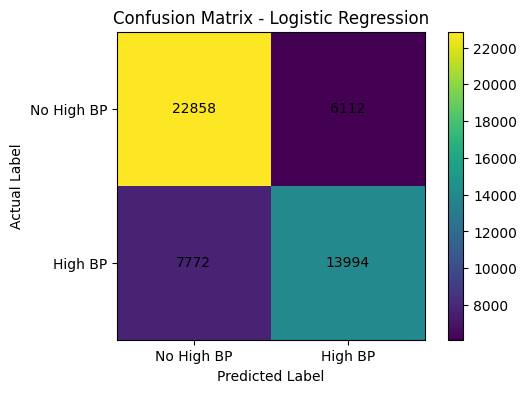

In [11]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Extract TN, FP, FN and TP
tn, fp, fn, tp = cm.ravel()

# Display confusion matrix
print("Confusion Matrix:")
print(cm)

print("\nTrue Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))
plt.imshow(cm)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["No High BP", "High BP"])
plt.yticks([0, 1], ["No High BP", "High BP"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

# Step 8: Classification Evaluation Metrics

Evaluate the Logistic Regression model using accuracy, precision, recall and F1-score.

- Accuracy measures the overall correctness of predictions.
- Precision measures how many predicted positive cases are actually positive.
- Recall measures how many actual positive cases are correctly identified.
- F1-score represents the balance between precision and recall.

These metrics provide a better understanding of model performance beyond accuracy.

In [ ]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Display results
print("Logistic Regression Evaluation")
print("--------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

# Display detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Step 9: False Positive vs False Negative Analysis

In healthcare screening, false positives and false negatives have different consequences.

- False Positive (FP): The model predicts high blood pressure when the actual condition is absent. This may result in unnecessary follow-up checks.
- False Negative (FN): The model predicts no high blood pressure when the person actually has high blood pressure. This may cause the person to miss further screening or medical attention.

In this healthcare-related classification task, false negatives can be particularly concerning because actual high blood pressure cases may be missed.

Therefore, recall is an important metric to consider. However, both false positives and false negatives should be evaluated carefully.

This model is intended for educational analysis and is not a medical diagnostic tool.

In [12]:
# Display false positive and false negative counts
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)

# Compare the two error types
if fn > fp:
    print("\nThe model produces more false negatives than false positives.")
elif fp > fn:
    print("\nThe model produces more false positives than false negatives.")
else:
    print("\nThe model produces equal numbers of false positives and false negatives.")

False Positive (FP): 6112
False Negative (FN): 7772

The model produces more false negatives than false positives.


# Step 10: 5-Fold Cross-Validation

Cross-validation evaluates model performance across multiple subsets of the dataset.

In 5-fold cross-validation, the dataset is divided into five parts. The model trains on four parts and validates on the remaining part. This process is repeated five times.

The mean accuracy provides an estimate of how consistently the model performs across different data splits.

The machine learning pipeline ensures that feature scaling is performed separately within each training fold, preventing data leakage.

In [13]:
# Perform 5-fold cross-validation
cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("5-Fold Cross-Validation Scores:")
print(cv_scores)

print("\nMean Cross-Validation Accuracy:",
      round(cv_scores.mean(), 4))

print("Standard Deviation:",
      round(cv_scores.std(), 4))

5-Fold Cross-Validation Scores:
[0.72392384 0.71868102 0.72309603 0.72536266 0.72656496]

Mean Cross-Validation Accuracy: 0.7235
Standard Deviation: 0.0027


# Step 11: Build Multiple Machine Learning Pipelines

Create three classification models:

1. Logistic Regression
2. Decision Tree
3. Gaussian Naive Bayes

Each model is combined with StandardScaler using a Pipeline.

These models will be compared using the same training and testing datasets.

In [14]:
# Create three machine learning pipelines
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(
            max_depth=6,
            random_state=42
        ))
    ]),

    "Gaussian Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ])
}

print("Three machine learning pipelines created successfully!")
print("Available models:", list(models.keys()))

Three machine learning pipelines created successfully!
Available models: ['Logistic Regression', 'Decision Tree', 'Gaussian Naive Bayes']


# Step 12: Model Evaluation and Comparison

Train all three classification models using the same training dataset.

Evaluate their performance on the same testing dataset using:

- Accuracy
- Precision
- Recall
- F1-score

Display the results in a comparison table to identify the strengths and weaknesses of each model.

In [15]:
# Store model evaluation results
results = []

for name, clf in models.items():

    # Train the model
    clf.fit(X_train, y_train)

    # Predict test data
    predictions = clf.predict(X_test)

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

# Create comparison DataFrame
results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(results_df.round(4))

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7263,0.6960,0.6429,0.6684
1,Decision Tree,0.7186,0.6766,0.6592,0.6678
2,Gaussian Naive Bayes,0.6804,0.6723,0.4977,0.5720


# Step 13: Model Performance Visualization

Visualize the accuracy, precision, recall and F1-score of all three classification models.

The comparison chart helps identify differences in model performance.

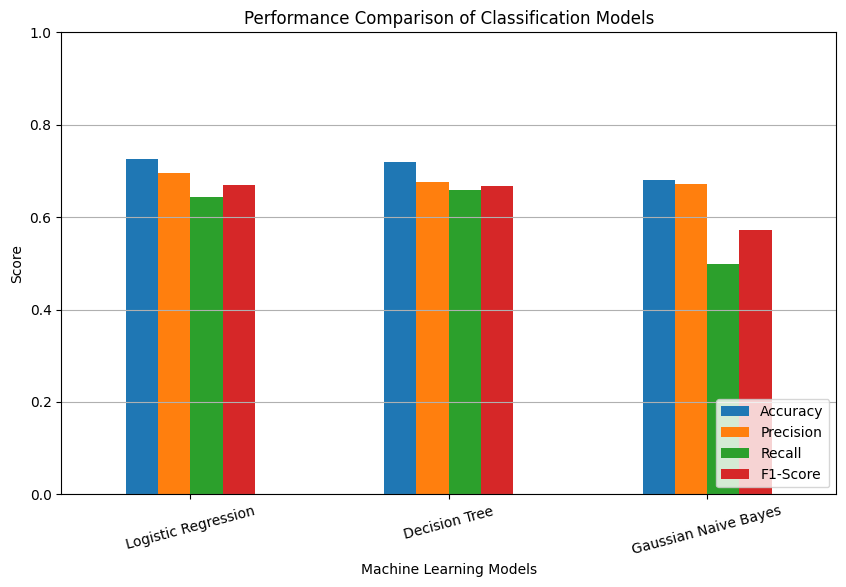

In [16]:
# Plot model performance
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

# Step 14: Cross-Validation Model Comparison

Evaluate all three classification models using 5-fold cross-validation.

Compare their mean accuracy and standard deviation to understand how consistently each model performs across different data splits.

In [18]:
# Compare 5-fold cross-validation accuracy
cv_results = []

for name, clf in models.items():

    scores = cross_val_score(
        clf,
        X,
        y,
        cv=5,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

# Create comparison table
cv_df = pd.DataFrame(cv_results)

print("5-Fold Cross-Validation Comparison:")
display(cv_df.round(4))

5-Fold Cross-Validation Comparison:


,Model,Mean CV Accuracy,Standard Deviation
0,Logistic Regression,0.7235,0.0027
1,Decision Tree,0.7157,0.0027
2,Gaussian Naive Bayes,0.6805,0.0033


# Step 15: Model Recommendation

Compare the three classification models using their accuracy, precision, recall, F1-score and cross-validation results.

Select the model with the highest F1-score as the recommended model, while also considering its recall and cross-validation performance.

Discuss the selected model's strengths and weaknesses, particularly its ability to identify high blood pressure cases and its false positive and false negative predictions.

In [20]:
# Identify the model with the highest F1-score
best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Recommended Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1-Score:", round(best_model["F1-Score"], 4))

# Display cross-validation performance
best_cv = cv_df.loc[
    cv_df["Model"] == best_model["Model"]
].iloc[0]

print("\nMean 5-Fold CV Accuracy:",
      round(best_cv["Mean CV Accuracy"], 4))

Recommended Model: Logistic Regression
Accuracy: 0.7263
Precision: 0.696
Recall: 0.6429
F1-Score: 0.6684

Mean 5-Fold CV Accuracy: 0.7235


# Step 16: Conclusion

In this assignment, different classification evaluation techniques were implemented using the CDC Diabetes Health Indicators dataset.

The Logistic Regression model was evaluated using a confusion matrix, accuracy, precision, recall and F1-score. Five-fold cross-validation was performed to examine model consistency.

Logistic Regression, Decision Tree and Gaussian Naive Bayes were compared using the same testing dataset.

The experiment demonstrates why accuracy alone is insufficient for evaluating classification models. Precision, recall, F1-score and cross-validation provide a broader understanding of classification performance and help identify the strengths and weaknesses of different machine learning models.